In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

Dataset imported from Kaggle

In [2]:
df=pd.read_csv("/content/train.csv")

In [3]:
df.head(2)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94


In [24]:
df['Sales'].describe()

,Sales
count,9800.000000
mean,230.769059
std,626.651875
min,0.444000
25%,17.248000
50%,54.490000
75%,210.605000
max,22638.480000


In [22]:
df.shape

(9800, 18)

In [5]:
df.dtypes

,0
Row ID,int64
Order ID,object
Order Date,object
Ship Date,object
Ship Mode,object
Customer ID,object
Customer Name,object
Segment,object
Country,object
City,object


In [6]:
print("Null count",df.isnull().sum())

Null count Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
dtype: int64


In [7]:
print("duplicate values",df.duplicated().sum())

duplicate values 0


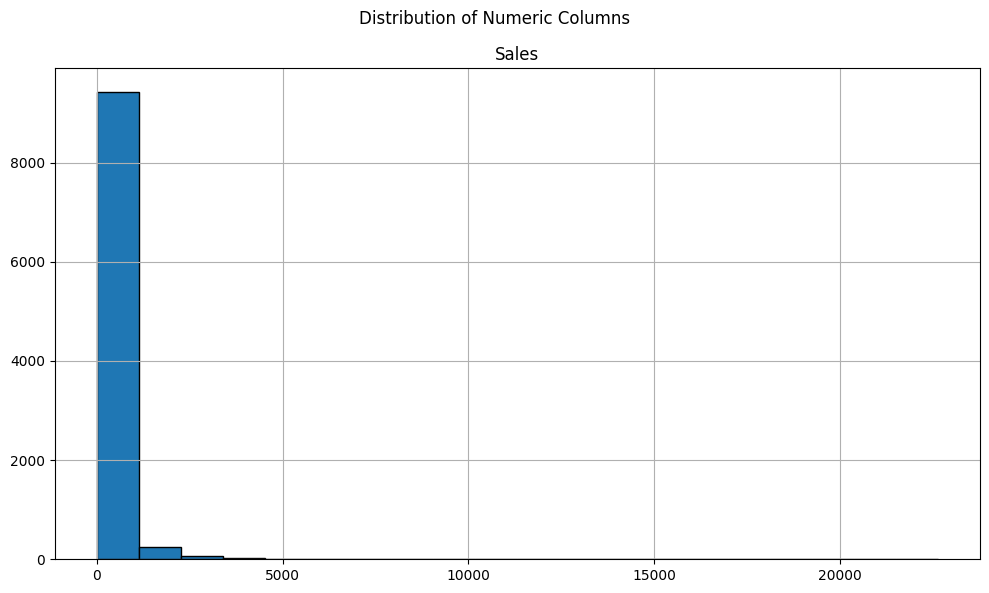

In [11]:
# Select all numeric columns as a list of column names
numeric_cols = ['Sales']

# Plot a histogram for every numeric column
df[numeric_cols].hist(
    bins=20,
    figsize=(10, 6),
    edgecolor="black"
)

plt.suptitle("Distribution of Numeric Columns")
plt.tight_layout()
plt.show()

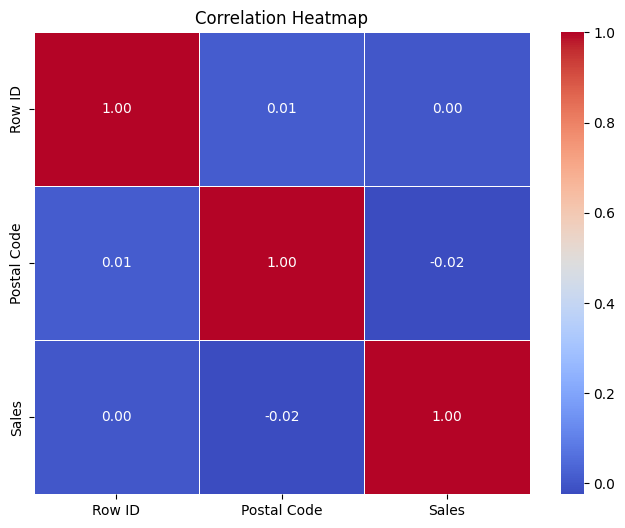

In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate correlation matrix for numeric columns
numeric_df = df.select_dtypes(include=['float64', 'int64'])
corr_matrix = numeric_df.corr()

# Create a correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

The above heat map doesn't suit for this Dataset

In [13]:
# Summary statistics for numerical columns
print("--- Numerical Columns Summary ---")
display(df[['Sales']].describe())

# Summary statistics for categorical columns
print("\n--- Categorical Columns Summary ---")
display(df.describe(include=['O']))

--- Numerical Columns Summary ---


,Sales
count,9800.000000
mean,230.769059
std,626.651875
min,0.444000
25%,17.248000
50%,54.490000
75%,210.605000
max,22638.480000



--- Categorical Columns Summary ---


,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Region,Product ID,Category,Sub-Category,Product Name
count,9800,9800,9800,9800,9800,9800,9800,9800,9800,9800,9800,9800,9800,9800,9800
unique,4922,1230,1326,4,793,793,3,1,529,49,4,1861,3,17,1849
top,CA-2018-100111,05/09/2017,26/09/2018,Standard Class,WB-21850,William Brown,Consumer,United States,New York City,California,West,OFF-PA-10001970,Office Supplies,Binders,Staple envelope
freq,14,38,34,5859,35,35,5101,9800,891,1946,3140,19,5909,1492,47


# Business Insights

##1. Calculating the total sales by category

Category
Furniture          728658.5757
Office Supplies    705422.3340
Technology         827455.8730
Name: Sales, dtype: float64


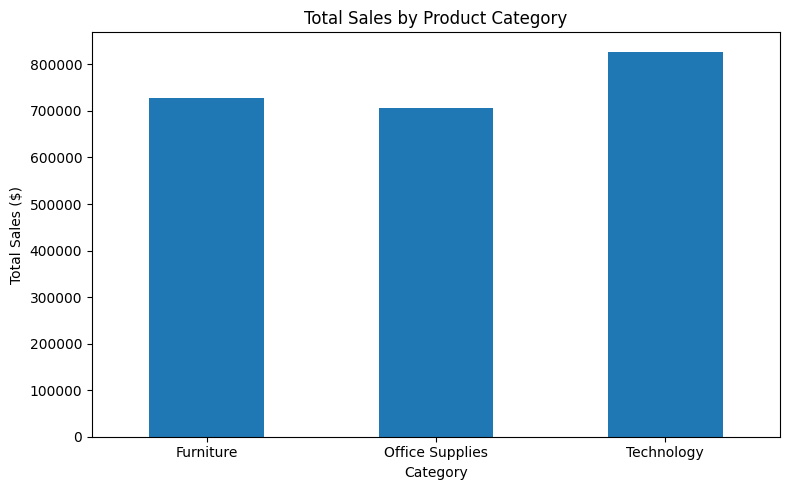

In [36]:
# Calculate sales by category
category_sales = (
    df.groupby("Category")["Sales"]
    .sum()
)

print(category_sales)

# using bar plot for visulaziation
category_sales.plot(kind="bar", figsize=(8, 5))

plt.title("Total Sales by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

##2. This business context to findout wchich type of segment are purchasing which type of sub category.

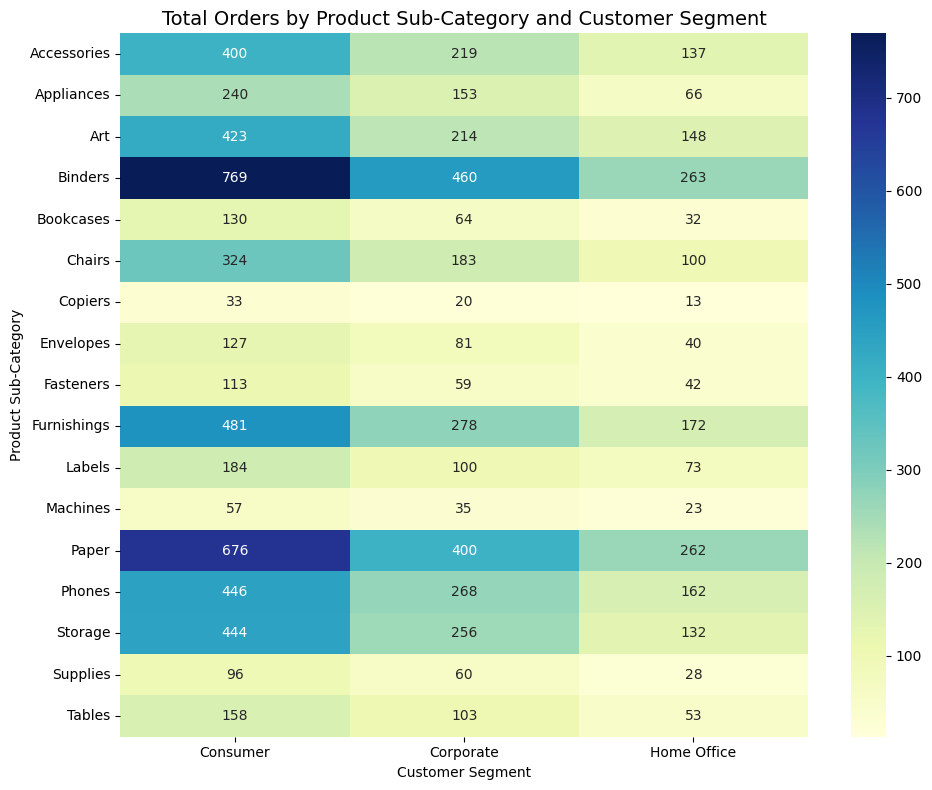

In [35]:
# 1. Create the summary table for the ENTIRE dataset
pivot = pd.pivot_table(
    df,
    index="Sub-Category",
    columns="Segment",
    values="Order ID",
    aggfunc="count",
    fill_value=0,
)

# 2. Plot it using Heat map
plt.figure(figsize=(10, 8))
sns.heatmap(pivot, annot=True, fmt="g", cmap="YlGnBu")

# 3. Add clear title
plt.title("Total Orders by Product Sub-Category and Customer Segment", fontsize=14)
plt.xlabel("Customer Segment")
plt.ylabel("Product Sub-Category")
plt.tight_layout()
plt.show()


## 3. groupyby the category of product of sales according to region

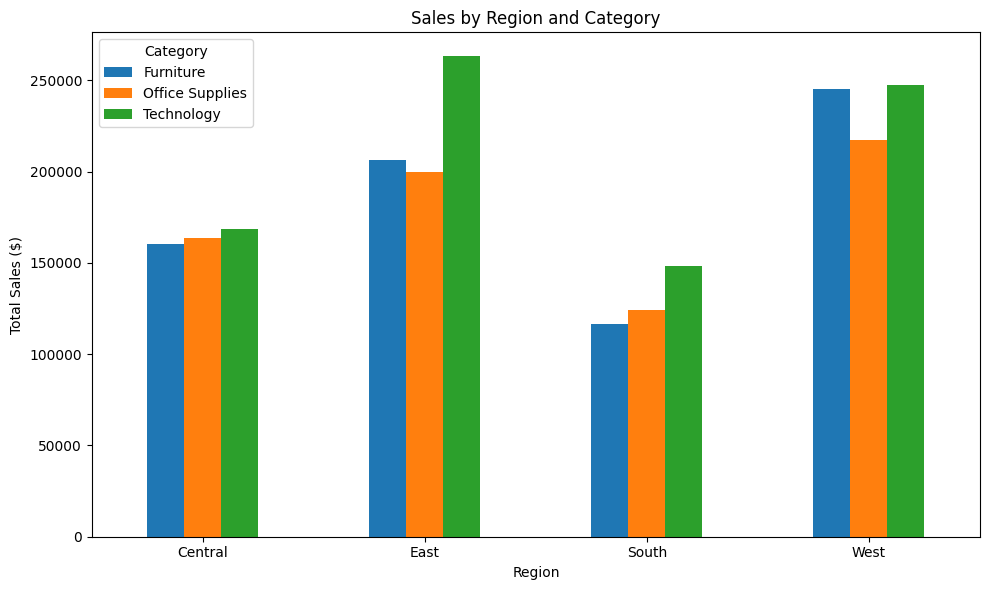

In [38]:
# Pivot columns into region and sum the sales according to category
pivot = sales_region_category.pivot(
    index="Region",
    columns="Category",
    values="Sales"
)

# Create the grouped bar chart
pivot.plot(kind="bar", figsize=(10, 6))

plt.title("Sales by Region and Category")
plt.xlabel("Region")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=0)
plt.legend(title="Category")
plt.tight_layout()
plt.show()

## 4. top 10 cities by sales.

Top 10 cities by sales:
City
New York City    252462.5470
Los Angeles      173420.1810
Seattle          116106.3220
San Francisco    109041.1200
Philadelphia     108841.7490
Houston           63956.1428
Chicago           47820.1330
San Diego         47521.0290
Jacksonville      44713.1830
Detroit           42446.9440
Name: Sales, dtype: float64


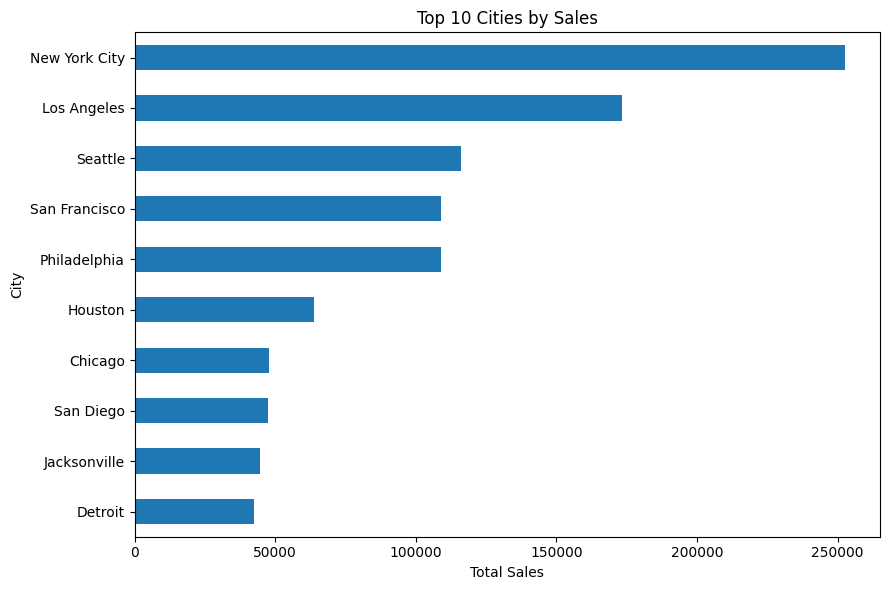

In [44]:
city_sales = (
    df.groupby("City")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

print("Top 10 cities by sales:")
print(city_sales.head(10))

city_sales.head(10).sort_values().plot(
    kind="barh", figsize=(9, 6)
)

plt.title("Top 10 Cities by Sales")
plt.xlabel("Total Sales")
plt.ylabel("City")
plt.tight_layout()
plt.show()

## 5. yearly sales trend according to sales

Year
2015    479856.2081
2016    459436.0054
2017    600192.5500
2018    722052.0192
Name: Sales, dtype: float64


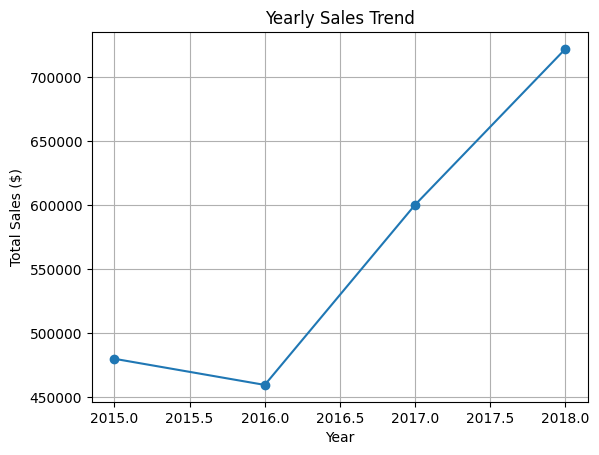

In [43]:
# Extracting year from column
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%d/%m/%Y")
df["Year"] = df["Order Date"].dt.year

# Calculate annual sales
yearly_sales = (
    df.groupby("Year")["Sales"]
    .sum()
    .sort_index()
)

print(yearly_sales)

# using line plot for yearly salestrend
yearly_sales.plot(
    kind="line",
    marker="o"
)

plt.title("Yearly Sales Trend")
plt.xlabel("Year")
plt.ylabel("Total Sales ($)")
plt.grid(True)
plt.show()